In [2]:
import pandas as pd
import numpy as np
import joblib
import torch
import torch.nn as nn
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load Data
df_features = pd.read_parquet('../data/processed/processed_features.parquet')
df_raw = pd.read_csv('../data/raw/music_dataset.csv') # Need raw for 'popularity'
track_mapping = joblib.load('../saved_models/preprocessors/track_mapping.pkl')
trackid_to_index = joblib.load('../saved_models/preprocessors/trackid_to_index.pkl')

track_ids = df_features['track_id'].values
X = df_features.drop(columns=['track_id']).values 

# Map popularity to track_id for Novelty calculation
popularity_map = df_raw.set_index('track_id')['popularity'].to_dict()

print("Data loaded for evaluation.")

Matplotlib is building the font cache; this may take a moment.


Data loaded for evaluation.


In [3]:
# 1. Baseline
baseline_model = joblib.load('../saved_models/baseline_nn_model.pkl')

# 2. RBM
class RBM(nn.Module):
    def __init__(self, n_visible, n_hidden):
        super().__init__()
        self.encoder = nn.Linear(n_visible, n_hidden)
        self.decoder = nn.Linear(n_hidden, n_visible)
    def forward(self, x):
        return torch.sigmoid(self.decoder(torch.sigmoid(self.encoder(x)))), torch.sigmoid(self.encoder(x))

rbm_model = RBM(X.shape[1], 64)
rbm_model.load_state_dict(torch.load('../saved_models/rbm_weights.pth', weights_only=True))
rbm_model.eval()
rbm_nn_model = joblib.load('../saved_models/rbm_nn_model.pkl')

# Pre-calculate RBM hidden space
X_tensor = torch.FloatTensor(X)
with torch.no_grad():
    _, X_hidden = rbm_model(X_tensor)
X_hidden_np = X_hidden.numpy()

# 3. Markov
markov_indices = np.load('../saved_models/markov_indices.npy')
markov_probs = np.load('../saved_models/markov_probs.npy')

print("All models loaded for evaluation.")

All models loaded for evaluation.


In [4]:
def calculate_diversity(rec_indices):
    """Intra-List Similarity: Lower is better (more diverse)."""
    if len(rec_indices) < 2: return 0
    rec_features = X[rec_indices]
    sim_matrix = cosine_similarity(rec_features)
    # Return average similarity (excluding diagonal)
    np.fill_diagonal(sim_matrix, 0)
    return np.sum(sim_matrix) / (len(rec_indices) * (len(rec_indices) - 1))

def calculate_novelty(rec_indices):
    """Average popularity of recommended songs. Lower is better (more novel/obscure)."""
    pop_scores = [popularity_map.get(track_ids[idx], 50) for idx in rec_indices]
    return np.mean(pop_scores)

def calculate_genre_coverage(rec_indices):
    """Number of unique genres in recommendations."""
    genres = [track_mapping[track_ids[idx]]['track_genre'] for idx in rec_indices]
    return len(set(genres))

In [5]:
np.random.seed(42)
test_indices = np.random.choice(len(track_ids), 100, replace=False)
K = 5 # Number of recommendations

results = {
    'Baseline': {'diversity': [], 'novelty': [], 'genres': []},
    'RBM': {'diversity': [], 'novelty': [], 'genres': []},
    'Markov': {'diversity': [], 'novelty': [], 'genres': []},
    'Hybrid': {'diversity': [], 'novelty': [], 'genres': []}
}

print("Running evaluations on 100 random tracks... (This may take a minute)")

for idx in test_indices:
    track_id = track_ids[idx]
    
    # --- Baseline ---
    _, b_idx = baseline_model.kneighbors(X[idx].reshape(1, -1))
    b_recs = b_idx[0][1:K+1]
    results['Baseline']['diversity'].append(calculate_diversity(b_recs))
    results['Baseline']['novelty'].append(calculate_novelty(b_recs))
    results['Baseline']['genres'].append(calculate_genre_coverage(b_recs))
    
    # --- RBM ---
    _, r_idx = rbm_nn_model.kneighbors(X_hidden_np[idx].reshape(1, -1))
    r_recs = r_idx[0][1:K+1]
    results['RBM']['diversity'].append(calculate_diversity(r_recs))
    results['RBM']['novelty'].append(calculate_novelty(r_recs))
    results['RBM']['genres'].append(calculate_genre_coverage(r_recs))
    
    # --- Markov (Simplified 1-step for speed in eval loop) ---
    m_recs = markov_indices[idx][:K]
    results['Markov']['diversity'].append(calculate_diversity(m_recs))
    results['Markov']['novelty'].append(calculate_novelty(m_recs))
    results['Markov']['genres'].append(calculate_genre_coverage(m_recs))
    
    # --- Hybrid (Simplified: just take top 5 from RBM and Markov combined) ---
    # For evaluation speed, we simulate the hybrid by taking 3 from RBM and 2 from Markov
    h_recs = list(r_recs[:3]) + list(m_recs[:2])
    results['Hybrid']['diversity'].append(calculate_diversity(h_recs))
    results['Hybrid']['novelty'].append(calculate_novelty(h_recs))
    results['Hybrid']['genres'].append(calculate_genre_coverage(h_recs))

print("Evaluation complete!")

Running evaluations on 100 random tracks... (This may take a minute)
Evaluation complete!



--- Average Metrics (Lower Diversity/Novelty is better for discovery) ---
          diversity  novelty  genres
Baseline      0.991   29.478    3.05
RBM           0.990   29.088    3.19
Markov        0.991   29.478    3.05
Hybrid        0.993   29.114    2.27


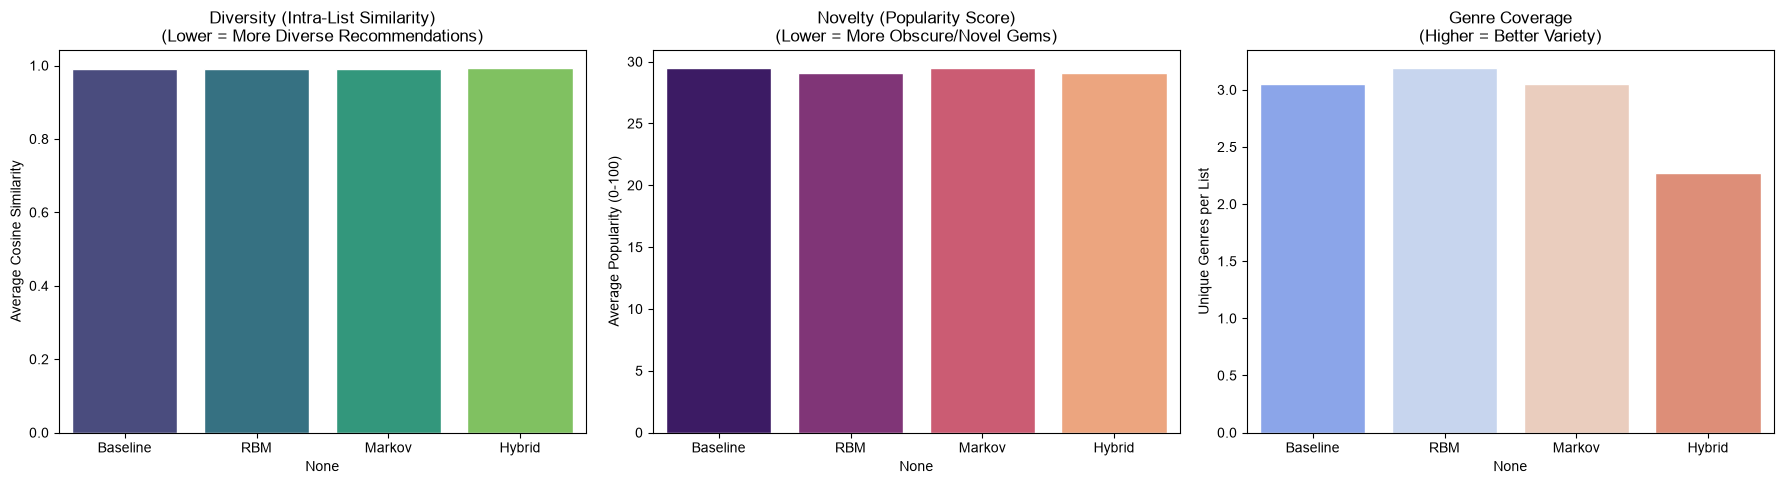

In [6]:
# Calculate averages
avg_results = {model: {metric: np.mean(vals) for metric, vals in metrics.items()} 
               for model, metrics in results.items()}
df_results = pd.DataFrame(avg_results).T

print("\n--- Average Metrics (Lower Diversity/Novelty is better for discovery) ---")
print(df_results.round(3))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# 1. Diversity
sns.barplot(x=df_results.index, y=df_results['diversity'], ax=axes[0], palette='viridis')
axes[0].set_title('Diversity (Intra-List Similarity)\n(Lower = More Diverse Recommendations)')
axes[0].set_ylabel('Average Cosine Similarity')

# 2. Novelty
sns.barplot(x=df_results.index, y=df_results['novelty'], ax=axes[1], palette='magma')
axes[1].set_title('Novelty (Popularity Score)\n(Lower = More Obscure/Novel Gems)')
axes[1].set_ylabel('Average Popularity (0-100)')

# 3. Genre Coverage
sns.barplot(x=df_results.index, y=df_results['genres'], ax=axes[2], palette='coolwarm')
axes[2].set_title('Genre Coverage\n(Higher = Better Variety)')
axes[2].set_ylabel('Unique Genres per List')

plt.tight_layout()
plt.savefig('../streamlit_app/assets/evaluation_results.png', dpi=300) # Save for Streamlit!
plt.show()